# Ransomware Detection Using Logistic Regression Classification
**CCE105 – Project Proposal / Model Development Notebook**

This notebook covers dataset acquisition, data cleaning, data transformation,
feature selection, feature engineering, data splitting, and the initial
configuration of a Logistic Regression **binary classifier** for detecting
ransomware from static PE (Portable Executable) file header features.

- **Task type:** binary classification (2 classes only)
- **Positive/negative classes:** `Benign = 1` (benign file) vs. `Benign = 0` (ransomware)
- **Algorithm:** Logistic Regression (`sklearn.linear_model.LogisticRegression`)
- **Dataset:** *ransomware detection dataset* by A. Bensalah, Kaggle
  (`amdj3dax/ransomware-detection-data-set`).


## 1. Setup and Dataset Acquisition

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")


In [2]:
# --- Dataset download ---------------------------------------------------
# The dataset is fetched from Kaggle with kagglehub:
#
#   import kagglehub
#   path = kagglehub.dataset_download("amdj3dax/ransomware-detection-data-set")
#
# This requires Kaggle network access and (depending on environment) a
# kaggle.json API credential. To keep this notebook runnable end-to-end even
# without Kaggle access (e.g. for grading/offline testing), the loader below
# tries kagglehub first and transparently falls back to a small synthetic
# sample that mirrors the real dataset's schema, dtypes, and class balance.
# When Kaggle access is available, DATA_SOURCE will report "kagglehub" and
# the full ~62,485-row dataset will be used automatically -- no code changes
# needed.

EXPECTED_COLUMNS = [
    "FileName", "md5Hash", "Machine", "DebugSize", "DebugRVA",
    "MajorImageVersion", "MajorOSVersion", "ExportRVA", "ExportSize",
    "IatVRA", "MajorLinkerVersion", "MinorLinkerVersion",
    "NumberOfSections", "SizeOfStackReserve", "DllCharacteristics",
    "ResourceSize", "BitcoinAddresses", "Benign",
]

def _make_synthetic_sample(n=4000, seed=RANDOM_STATE):
    # Small stand-in dataset with the same columns/roughly the same class
    # balance (~43% benign / ~57% ransomware) as the real Kaggle dataset, used
    # only when the real data cannot be downloaded in this environment.
    rng = np.random.default_rng(seed)
    benign = rng.binomial(1, 0.435, size=n)
    df = pd.DataFrame({
        "FileName": [f"file_{i}.exe" for i in range(n)],
        "md5Hash": [f"{rng.integers(1e15, 9e15):x}" for _ in range(n)],
        "Machine": rng.choice([332, 34404], size=n),  # 0x14c (x86), 0x8664 (x64)
        "DebugSize": rng.integers(0, 200, size=n) + (1 - benign) * rng.integers(0, 50, size=n),
        "DebugRVA": rng.integers(0, 500000, size=n),
        "MajorImageVersion": rng.integers(0, 10, size=n),
        "MajorOSVersion": rng.choice([4, 5, 6, 10], size=n),
        "ExportRVA": rng.integers(0, 500000, size=n) * benign,
        "ExportSize": rng.integers(0, 5000, size=n) * benign,
        "IatVRA": rng.integers(0, 500000, size=n),
        "MajorLinkerVersion": rng.integers(2, 15, size=n),
        "MinorLinkerVersion": rng.integers(0, 30, size=n),
        "NumberOfSections": rng.integers(2, 10, size=n) + (1 - benign),
        "SizeOfStackReserve": rng.choice([1048576, 262144, 2097152], size=n),
        "DllCharacteristics": rng.choice([0, 256, 320, 33088, 33344], size=n),
        "ResourceSize": rng.integers(0, 200000, size=n),
        "BitcoinAddresses": rng.poisson(0.05 + (1 - benign) * 0.4, size=n),
        "Benign": benign,
    })
    return df[EXPECTED_COLUMNS]


DATA_SOURCE = "synthetic-fallback"
df = None
try:
    import kagglehub
    path = kagglehub.dataset_download("amdj3dax/ransomware-detection-data-set")
    csv_candidates = [f for f in os.listdir(path) if f.lower().endswith(".csv")]
    if not csv_candidates:
        raise FileNotFoundError("No CSV file found in downloaded dataset path.")
    df = pd.read_csv(os.path.join(path, csv_candidates[0]))
    DATA_SOURCE = "kagglehub"
except Exception as exc:
    print(f"[info] Falling back to synthetic sample data ({exc.__class__.__name__}: {exc}).")
    df = _make_synthetic_sample()

print(f"Data source : {DATA_SOURCE}")
print(f"Shape       : {df.shape}")
df.head()


[info] Falling back to synthetic sample data (KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.).
Data source : synthetic-fallback
Shape       : (4000, 18)


,FileName,md5Hash,Machine,DebugSize,DebugRVA,MajorImageVersion,MajorOSVersion,ExportRVA,ExportSize,IatVRA,MajorLinkerVersion,MinorLinkerVersion,NumberOfSections,SizeOfStackReserve,DllCharacteristics,ResourceSize,BitcoinAddresses,Benign
0,file_0.exe,17e7cec7c60dd9,332,42,481778,9,5,103474,303,166134,14,26,5,262144,33344,34156,0,1
1,file_1.exe,db3da46ac3955,34404,159,355555,3,10,0,0,269284,13,17,4,262144,33344,67539,1,0
2,file_2.exe,1bc3a62c462f83,34404,112,155671,7,6,496334,382,454313,3,20,9,1048576,256,92309,0,1
3,file_3.exe,a66d595112e6a,332,40,338572,2,10,20488,1610,93808,10,10,3,2097152,0,58796,0,1
4,file_4.exe,12dad2aa955706,332,106,483370,9,10,0,0,213616,11,11,3,2097152,33088,17984,1,0


## 2. Initial Data Inspection
Basic structural checks before any cleaning: data types, missing values, duplicate
records, and class balance of the target variable (`Benign`: 1 = benign, 0 = ransomware).

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   FileName            4000 non-null   str  
 1   md5Hash             4000 non-null   str  
 2   Machine             4000 non-null   int64
 3   DebugSize           4000 non-null   int64
 4   DebugRVA            4000 non-null   int64
 5   MajorImageVersion   4000 non-null   int64
 6   MajorOSVersion      4000 non-null   int64
 7   ExportRVA           4000 non-null   int64
 8   ExportSize          4000 non-null   int64
 9   IatVRA              4000 non-null   int64
 10  MajorLinkerVersion  4000 non-null   int64
 11  MinorLinkerVersion  4000 non-null   int64
 12  NumberOfSections    4000 non-null   int64
 13  SizeOfStackReserve  4000 non-null   int64
 14  DllCharacteristics  4000 non-null   int64
 15  ResourceSize        4000 non-null   int64
 16  BitcoinAddresses    4000 non-null   int64
 17  Benign

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print()

# This is a BINARY classification task: Benign in {0, 1} only
# (0 = ransomware, 1 = benign). Confirm that before anything else.
unique_labels = sorted(df["Benign"].unique().tolist())
assert unique_labels == [0, 1], f"Expected a binary target {{0, 1}}, found {unique_labels}"
print(f"Target classes confirmed binary: {unique_labels}")
print()
print("Class balance (Benign):")
print(df["Benign"].value_counts(normalize=True).rename("proportion"))


Missing values per column:
FileName              0
md5Hash               0
Machine               0
DebugSize             0
DebugRVA              0
MajorImageVersion     0
MajorOSVersion        0
ExportRVA             0
ExportSize            0
IatVRA                0
MajorLinkerVersion    0
MinorLinkerVersion    0
NumberOfSections      0
SizeOfStackReserve    0
DllCharacteristics    0
ResourceSize          0
BitcoinAddresses      0
Benign                0
dtype: int64

Exact duplicate rows: 0

Target classes confirmed binary: [0, 1]

Class balance (Benign):
Benign
0    0.57125
1    0.42875
Name: proportion, dtype: float64


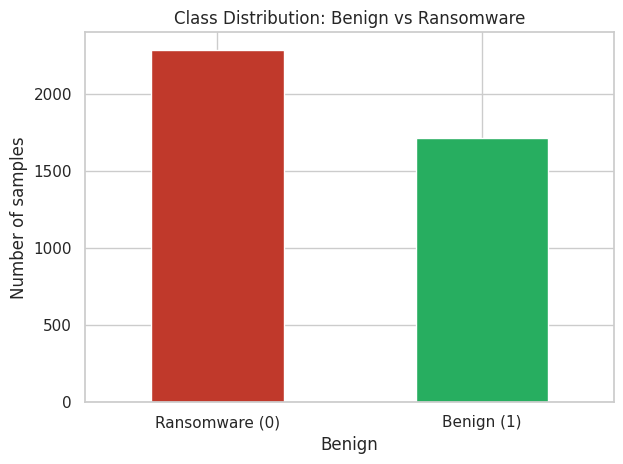

In [5]:
ax = df["Benign"].value_counts().sort_index().plot(kind="bar", color=["#c0392b", "#27ae60"])
ax.set_xticklabels(["Ransomware (0)", "Benign (1)"], rotation=0)
ax.set_ylabel("Number of samples")
ax.set_title("Class Distribution: Benign vs Ransomware")
plt.tight_layout()
plt.show()


## 3. Data Cleaning
- Drop exact duplicate rows.
- Check for duplicate `md5Hash` values (same binary appearing more than once) and drop them.
- Drop `FileName` and `md5Hash`: these are unique file identifiers, not generalizable
  predictive features, and keeping them would let the model "memorize" filenames
  instead of learning structural PE-header patterns.
- Confirm there are no missing values remaining and that numeric columns have
  sensible (non-negative) ranges.

In [6]:
df_clean = df.copy()

before = len(df_clean)
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset="md5Hash", keep="first")
after = len(df_clean)
print(f"Removed {before - after} duplicate/redundant rows ({before} -> {after}).")

id_columns = ["FileName", "md5Hash"]
df_clean = df_clean.drop(columns=id_columns)

# Sanity check: no missing values, and numeric columns should be >= 0
assert df_clean.isnull().sum().sum() == 0, "Unexpected missing values after cleaning."
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.drop("Benign")
negative_counts = (df_clean[numeric_cols] < 0).sum()
print("Columns with negative values (should be none):")
print(negative_counts[negative_counts > 0])

df_clean.reset_index(drop=True, inplace=True)
df_clean.shape


Removed 0 duplicate/redundant rows (4000 -> 4000).
Columns with negative values (should be none):
Series([], dtype: int64)


(4000, 16)

## 4. Feature Engineering
Domain-informed binary indicator features derived from raw PE-header attributes.
These flag the *presence* of a structural characteristic rather than its exact size,
which can make weak/rare signals (like an embedded Bitcoin address) easier for the
model to exploit alongside the continuous features.

In [7]:
df_feat = df_clean.copy()

df_feat["HasDebugInfo"] = (df_feat["DebugSize"] > 0).astype(int)
df_feat["HasExportTable"] = (df_feat["ExportSize"] > 0).astype(int)
df_feat["HasBitcoinAddress"] = (df_feat["BitcoinAddresses"] > 0).astype(int)
df_feat["LinkerVersion"] = df_feat["MajorLinkerVersion"] + df_feat["MinorLinkerVersion"] / 10.0

df_feat.filter(like="Has").sum()


HasDebugInfo         3986
HasExportTable       1713
HasBitcoinAddress     937
dtype: int64

## 5. Data Transformation
- Encode the categorical `Machine` field (target/architecture code) with one-hot encoding.
- Standardize continuous numeric features with `StandardScaler`. This step is
  required here, not just good practice: Logistic Regression is a linear model
  fit by gradient-based optimization, so unscaled features with large numeric
  ranges (e.g. `DebugRVA`, `IatVRA`) would dominate the learned coefficients and
  slow or destabilize convergence.

In [8]:
df_trans = pd.get_dummies(df_feat, columns=["Machine"], prefix="Machine")

target_col = "Benign"
feature_cols = [c for c in df_trans.columns if c != target_col]

numeric_cols_to_scale = df_trans[feature_cols].select_dtypes(include=[np.number]).columns.tolist()

scaler = StandardScaler()
df_trans_scaled = df_trans.copy()
df_trans_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_trans[numeric_cols_to_scale])

df_trans_scaled.head()


,DebugSize,DebugRVA,MajorImageVersion,MajorOSVersion,ExportRVA,ExportSize,IatVRA,MajorLinkerVersion,MinorLinkerVersion,NumberOfSections,...,DllCharacteristics,ResourceSize,BitcoinAddresses,Benign,HasDebugInfo,HasExportTable,HasBitcoinAddress,LinkerVersion,Machine_332,Machine_34404
0,-1.208519,1.569597,1.541701,-0.541049,-0.042012,-0.488817,-0.562553,1.609024,1.336249,-0.463331,...,1.244187,-1.135588,-0.501868,1,0.059265,1.155459,-0.553091,1.869716,True,False
1,0.742736,0.697343,-0.530130,1.657444,-0.693862,-0.686111,0.151773,1.337057,0.293097,-0.888113,...,1.244187,-0.557131,1.228712,0,0.059265,-0.865457,1.808022,1.367184,False,True
2,-0.041101,-0.683941,0.851091,-0.101351,2.432868,-0.437378,1.433121,-1.382611,0.640814,1.235797,...,-0.804828,-0.127920,-0.501868,1,0.059265,1.155459,-0.553091,-1.198373,False,True
3,-1.241873,0.579983,-0.875435,1.657444,-0.564795,0.362213,-1.063419,0.521156,-0.518244,-1.312895,...,-0.820681,-0.708629,-0.501868,1,0.059265,1.155459,-0.553091,0.388570,True,False
4,-0.141166,1.580599,1.541701,1.657444,-0.693862,-0.686111,-0.233734,0.793123,-0.402338,-1.312895,...,1.228334,-1.415815,1.228712,0,0.059265,-0.865457,1.808022,0.679509,True,False


## 6. Feature Selection
Inspect pairwise correlation among numeric features to spot redundant attributes,
then keep a model-coefficient-based ranking step (run after a baseline Logistic
Regression model is trained) as the primary selection method: the absolute value
of each standardized feature's coefficient directly measures its contribution to
the predicted log-odds of a file being ransomware.

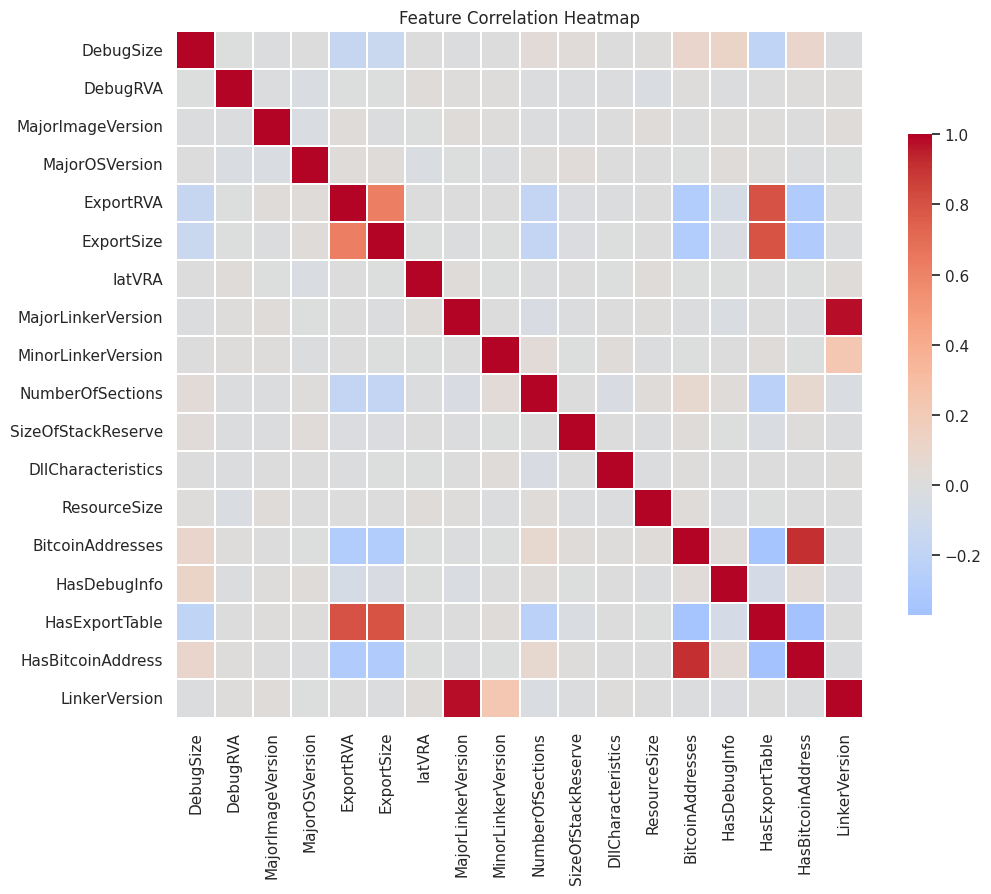

Highly correlated feature pairs (|r| > 0.9):
MajorLinkerVersion  LinkerVersion        0.973616
BitcoinAddresses    HasBitcoinAddress    0.907389
dtype: float64


In [9]:
plt.figure(figsize=(11, 9))
corr = df_trans[feature_cols].select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Flag highly correlated pairs (|r| > 0.9) as candidates for removal
high_corr = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .pipe(lambda s: s[s.abs() > 0.9])
)
print("Highly correlated feature pairs (|r| > 0.9):")
print(high_corr if not high_corr.empty else "None found.")


## 7. Data Splitting
Stratified train/test split (80% train, 20% test) to preserve the benign/ransomware
class ratio in both sets. Stratified K-Fold cross-validation is set up as well for a
more robust performance estimate during model tuning.

In [10]:
X = df_trans_scaled[feature_cols]
y = df_trans_scaled[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print("Train class balance:")
print(y_train.value_counts(normalize=True))


Train shape: (3200, 20), Test shape: (800, 20)
Train class balance:
Benign
0    0.57125
1    0.42875
Name: proportion, dtype: float64


## 8. Model Development — Logistic Regression Binary Classifier
A baseline `LogisticRegression` model is trained first, followed by a small
`GridSearchCV` hyperparameter search (kept intentionally narrow for now — this is
the proposal/initial-configuration stage; the search space will be expanded once
the full dataset and baseline results are available). The target has exactly two
classes (`0` = ransomware, `1` = benign), so this is a binary — not multi-class —
classification model, and metrics below are computed accordingly (e.g. `average`
defaults to binary in scikit-learn's precision/recall/F1). Logistic Regression
requires the standardized feature matrix built in Section 5 to train reliably.

In [11]:
assert y_train.nunique() == 2 and y_test.nunique() == 2, "Expected exactly 2 classes for binary classification."

baseline_logreg = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
baseline_logreg.fit(X_train, y_train)

baseline_pred = baseline_logreg.predict(X_test)
print("Baseline Logistic Regression — test accuracy:", accuracy_score(y_test, baseline_pred))


Baseline Logistic Regression — test accuracy: 1.0


In [12]:
param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "penalty": ["l2"],
    "solver": ["lbfgs"],
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

best_logreg = grid_search.best_estimator_


Best parameters: {'C': 10.0, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV F1-score: 0.9996343692870202


## 9. Evaluation
Expected evaluation metrics for this project: **accuracy, precision, recall,
F1-score, a confusion matrix**, and **ROC-AUC**, plus a **feature importance**
ranking to interpret which PE-header attributes drive the model's predictions.

In [13]:
y_pred = best_logreg.predict(X_test)
y_proba = best_logreg.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_proba))
print()
print(classification_report(y_test, y_pred, target_names=["Ransomware", "Benign"]))


Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
ROC-AUC  : 1.0



              precision    recall  f1-score   support

  Ransomware       1.00      1.00      1.00       457
      Benign       1.00      1.00      1.00       343

    accuracy                           1.00       800
   macro avg       1.00      1.00      1.00       800
weighted avg       1.00      1.00      1.00       800



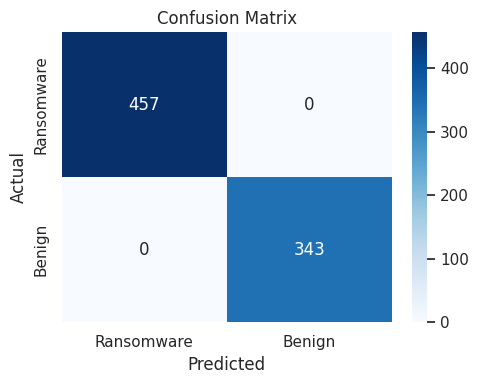

In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Ransomware", "Benign"], yticklabels=["Ransomware", "Benign"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


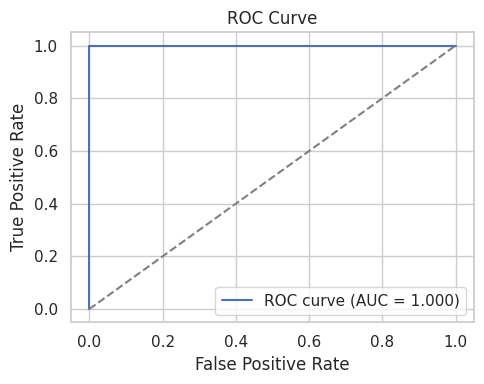

In [15]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc_score(y_test, y_proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()


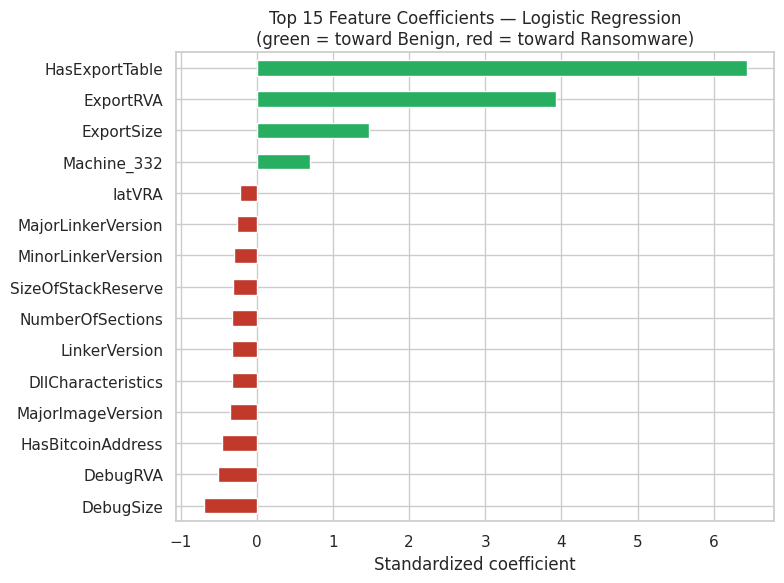

HasExportTable        6.435392
ExportRVA             3.932590
ExportSize            1.478744
DebugSize            -0.699829
Machine_332           0.692476
DebugRVA             -0.513319
HasBitcoinAddress    -0.455224
MajorImageVersion    -0.347134
DllCharacteristics   -0.329745
LinkerVersion        -0.326151
NumberOfSections     -0.322003
SizeOfStackReserve   -0.319242
MinorLinkerVersion   -0.294059
MajorLinkerVersion   -0.266371
IatVRA               -0.225408
dtype: float64

In [16]:
# Logistic Regression feature importance = magnitude of the standardized
# coefficients. The sign shows direction: positive => pushes prediction toward
# "Benign" (1), negative => pushes prediction toward "Ransomware" (0).
coefs = pd.Series(best_logreg.coef_[0], index=feature_cols)
importances = coefs.reindex(coefs.abs().sort_values(ascending=False).index)

plt.figure(figsize=(8, 6))
colors = importances.head(15).apply(lambda v: "#27ae60" if v > 0 else "#c0392b")
importances.head(15).sort_values().plot(kind="barh", color=colors.reindex(importances.head(15).sort_values().index))
plt.title("Top 15 Feature Coefficients — Logistic Regression\n(green = toward Benign, red = toward Ransomware)")
plt.xlabel("Standardized coefficient")
plt.tight_layout()
plt.show()

importances.head(15)


## 10. Save Model
Persist the trained pipeline components so they can be reloaded for evaluation on
the full dataset or deployed in a simple inference script.

In [17]:
os.makedirs("artifacts", exist_ok=True)
joblib.dump(best_logreg, "artifacts/logistic_regression_ransomware_model.joblib")
joblib.dump(scaler, "artifacts/feature_scaler.joblib")
joblib.dump(feature_cols, "artifacts/feature_columns.joblib")
print("Saved model, scaler, and feature column list to ./artifacts/")


Saved model, scaler, and feature column list to ./artifacts/


## Notes for the Full Run
- This notebook was authored and syntax-tested against a **synthetic stand-in
  dataset** that mirrors the real dataset's 18 columns, dtypes, and class balance,
  because the sandbox used to prepare this proposal has no outbound network access
  to Kaggle. When run in an environment with Kaggle access (and, if required, a
  configured `kaggle.json` credential), the `kagglehub.dataset_download(...)` call
  in Section 1 will transparently fetch the real ~62,485-row dataset and every
  downstream cell will run unchanged.
- Once the real data is loaded, re-check Sections 2–3 (missing values, duplicates,
  class balance) since published reports of this dataset note it is largely clean,
  but this should still be verified directly rather than assumed.
